1. Create a Google Colab notebook.
2. Use 🤗 Datasets to load the train split of the facebook/voxpopuli dataset in language of your choice in streaming mode.
3. Get the third example from the train part of the dataset and explore it. Given the features that this example has, what kinds of audio tasks can you use this dataset for?
4. Plot this example’s waveform and spectrogram.
5. Go to 🤗 Hub, explore pretrained models and find one that can be used for automatic speech recognition for the language that you have picked earlier. Instantiate a corresponding pipeline with the model you found, and transcribe the example.
6. Compare the transcription that you get from the pipeline to the transcription provided in the example.

In [34]:
import datasets
from datasets import load_dataset
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

voices = load_dataset("facebook/voxpopuli","it", split="train", streaming=True)

small_dataset = voices.take(1000)
print(small_dataset)
print(small_dataset.features["audio"])

IterableDataset({
    features: ['audio_id', 'language', 'audio', 'raw_text', 'normalized_text', 'gender', 'speaker_id', 'is_gold_transcript', 'accent'],
    num_shards: 5
})
Audio(sampling_rate=16000, decode=True, num_channels=None, stream_index=None)


-  array (Amplitude over time): A 1D list of floating-point numbers (typically between -1.0 and 1.0). Each number measures the air pressure (speaker cone position/loudness) of the sound wave at a tiny slice in time.
- sr / sampling_rate (Speed of snapshots): The number of audio samples recorded per second, measured in Hertz (Hz). In VoxPopuli, sr is 16,000 Hz, meaning there are 16,000 numbers in array for every 1 second of speech (so a 3-second clip has an array of length 48,000).

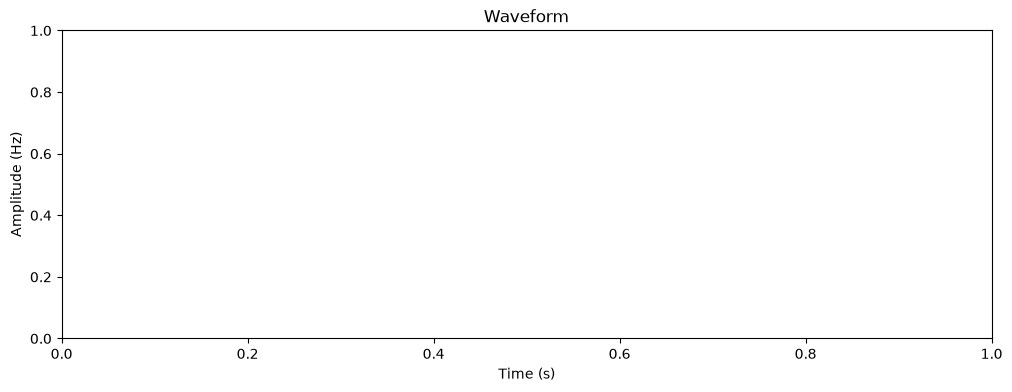

ImportError: Numba could not be imported.
--------------------------------------------------------------------------------
If you are seeing this message and are undertaking Numba development work, you may need to rebuild Numba.
Please see the development set up guide:

https://numba.readthedocs.io/en/stable/developer/contributing.html.

--------------------------------------------------------------------------------
If you are not working on Numba development, the original error was: 'DLL load failed while importing _typeconv: The specified module could not be found.'.
For help, please visit:

https://numba.readthedocs.io/en/stable/user/faq.html#numba-could-not-be-imported


In [38]:
#setting example and plotting waveform and spectrogram

example = small_dataset[3]
audio_array = example["audio"]["array"]
sr= example["audio"]["sampling_rate"]


#waveform
# time= np.linspace(0, len(audio_array)/ sr, num=len(audio_array)) or just librosa.display.waveshow(audio_array, sr=sr)
plt.figure(figsize=(12, 4))
#plt.plot(time, audio_array, linewidth=0.5)
plt.title("Waveform")
plt.xlabel("Time (s)") 
plt.ylabel("Amplitude (Hz)")
plt.show()


#spectrogram 
S= librosa.feature.melspectrogram(y=audio_array, sr=sr, n_mels=128)
S_dB = librosa.power_to_db(S, ref=np.max)

plt.figure(figsize=(12,4))#
librosa.display.specshow(S_db, x_axis="time", y_axis="mel", sr=sr)
plt.colorbar()


In [39]:
from transformers import pipeline

transcription_pipe = pipeline("automatic-speech-recognition", model="Reson8/Rumble-2-Flash")
transcription_pipe(example["audio"]["array"])

ImportError: DLL load failed while importing soxr_ext: The specified module could not be found.

In [40]:
example["audio"]["array"]